In [1]:
import glob, h5py, matplotlib.pyplot as plt
from data import ROOT, split
train_ids, val_ids = split()
print(len(train_ids), 'soggetti train;', len(val_ids), 'val')
paths = sorted(glob.glob(ROOT + val_ids[0] + '/*.h5'))
print(len(paths), 'scan nel soggetto', val_ids[0]); [print(p.split('/')[-1]) for p in paths]

45 soggetti train; 5 val
24 scan nel soggetto 001
LH_Par_C_DtP.h5
LH_Par_C_PtD.h5
LH_Par_L_DtP.h5
LH_Par_L_PtD.h5
LH_Par_S_DtP.h5
LH_Par_S_PtD.h5
LH_Per_C_DtP.h5
LH_Per_C_PtD.h5
LH_Per_L_DtP.h5
LH_Per_L_PtD.h5
LH_Per_S_DtP.h5
LH_Per_S_PtD.h5
RH_Par_C_DtP.h5
RH_Par_C_PtD.h5
RH_Par_L_DtP.h5
RH_Par_L_PtD.h5
RH_Par_S_DtP.h5
RH_Par_S_PtD.h5
RH_Per_C_DtP.h5
RH_Per_C_PtD.h5
RH_Per_L_DtP.h5
RH_Per_L_PtD.h5
RH_Per_S_DtP.h5
RH_Per_S_PtD.h5


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [2]:
f = h5py.File(paths[0], 'r')
for k in f: print(k, f[k].shape, f[k].dtype)
frames, tforms = f['frames'][:], f['tforms'][:]
print(tforms[0]); print(tforms[100])

frames (584, 480, 640) uint8
tforms (584, 4, 4) float32
[[-1.8151265e-01 -9.8242241e-01  4.3581218e-02  2.1040792e+01]
 [ 8.0561610e-03 -4.5801438e-02 -9.9891806e-01  1.2414677e+02]
 [ 9.8335558e-01 -1.8096517e-01  1.6228095e-02 -8.1155048e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  1.0000000e+00]]
[[-1.1737040e-01 -9.9242800e-01  3.6205884e-02  2.7163664e+01]
 [-3.8636018e-02 -3.1867024e-02 -9.9874508e-01  9.4359222e+01]
 [ 9.9233633e-01 -1.1862196e-01 -3.4603219e-02 -8.3019946e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  1.0000000e+00]]


Alcuni frame dello scan:

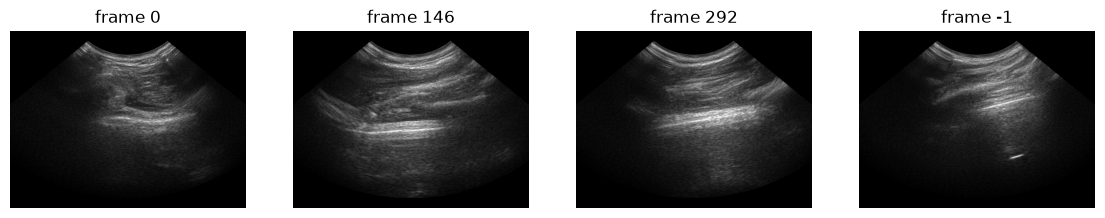

In [3]:
idx = [0, len(frames)//4, len(frames)//2, -1]
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, i in zip(ax, idx): a.imshow(frames[i], cmap='gray'); a.set_title(f'frame {i}'); a.axis('off')

Traiettoria della sonda (posizione = ultima colonna di ogni matrice, unità del file).

(np.float64(18.728878211975097),
 np.float64(69.15052013397217),
 np.float64(-99.02922248840332),
 np.float64(134.77419471740723))

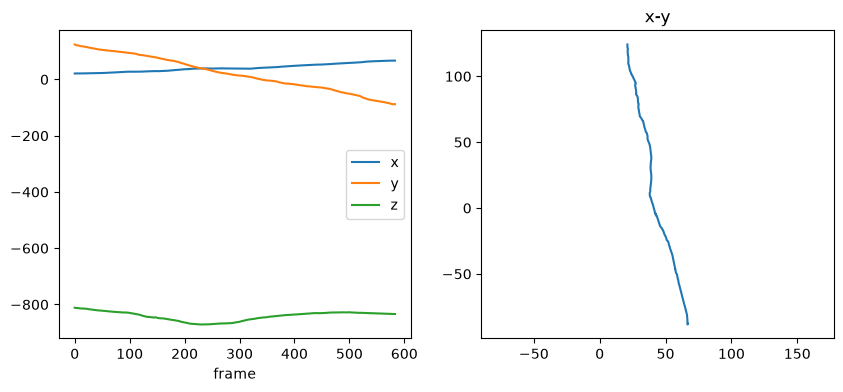

In [4]:
t = tforms[:, :3, 3]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(t); ax[0].legend('xyz'); ax[0].set_xlabel('frame')
ax[1].plot(t[:, 0], t[:, 1]); ax[1].set_title('x-y'); ax[1].axis('equal')

Come li vede il modello (`Clips`): clip di L frame ridimensionati, pose relative al primo frame (T_{i→0}, mm).

In [5]:
from data import Clips
x, T = Clips(val_ids, L=32, stride=2)[0]
print(x.shape, x.min().item(), x.max().item(), T.shape)
print(T[0])  # identità
print(T[-1])

torch.Size([32, 1, 120, 160]) 0.0 0.8009804487228394 torch.Size([32, 4, 4])
tensor([[ 1.0000e+00, -2.7756e-17, -5.5511e-17,  3.5527e-14],
        [ 1.1102e-16,  1.0000e+00, -2.7756e-17,  1.4211e-14],
        [-1.6653e-16,  2.3731e-15,  1.0000e+00,  4.3343e-13],
        [-1.6126e-19, -8.1390e-19, -1.5207e-19,  1.0000e+00]])
tensor([[ 9.9899e-01, -4.3872e-03,  4.4651e-02,  1.1589e+01],
        [ 2.0773e-03,  9.9866e-01,  5.1648e-02, -9.5727e-01],
        [-4.4818e-02, -5.1503e-02,  9.9767e-01, -1.9869e+01],
        [-1.5598e-19, -8.0428e-19, -2.0095e-19,  1.0000e+00]])
